# Retail Sales Data — Exploratory Data Analysis
**OASIS INFOBYTE SIP | Data Analytics | Level 1, Task 1**

This notebook explores a bundled synthetic retail dataset. It demonstrates the required analysis workflow; findings are illustrative and should not be described as real company results.

## 1. Imports and dataset loading
Load the CSV and inspect its dimensions, data types, missing values, and duplicate rows.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE = Path.cwd()
if not (BASE / 'data' / 'retail_sales.csv').exists():
    BASE = Path('OIBSIP/DataAnalytics-L1-EDARetailSales')
DATA = BASE / 'data' / 'retail_sales.csv'
OUT = BASE / 'outputs'
OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
df = pd.read_csv(DATA, parse_dates=['Date'])
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df['Month'] = df['Date'].dt.to_period('M').astype(str)
df['Quarter'] = df['Date'].dt.to_period('Q').astype(str)
df['AgeGroup'] = pd.cut(df['CustomerAge'], bins=[17,24,34,44,54,64,100], labels=['18–24','25–34','35–44','45–54','55–64','65+'])
print('Shape:', df.shape)
display(df.head())
print('\nData types:\n', df.dtypes)
print('\nMissing values:\n', df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())

Shape: (1200, 14)


,TransactionID,Date,CustomerAge,Gender,Product,Category,Quantity,UnitPrice,PaymentMethod,Region,Revenue,Month,Quarter,AgeGroup
0,TXN00001,2025-02-02,48,Male,Running Shoes,Clothing,1,1791.11,UPI,Central,1791.11,2025-02,2025Q1,45–54
1,TXN00002,2025-10-10,41,Female,Sunscreen,Beauty,1,971.50,UPI,North,971.50,2025-10,2025Q4,35–44
2,TXN00003,2025-08-27,26,Female,Mystery Novel,Books,2,707.40,UPI,West,1414.80,2025-08,2025Q3,25–34
3,TXN00004,2025-06-10,29,Female,Sunscreen,Beauty,1,1081.80,UPI,Central,1081.80,2025-06,2025Q2,25–34
4,TXN00005,2025-06-08,40,Male,Notebook,Books,4,748.50,Debit Card,Central,2994.00,2025-06,2025Q2,35–44



Data types:
 TransactionID            object
Date             datetime64[ns]
CustomerAge               int64
Gender                   object
Product                  object
Category                 object
Quantity                  int64
UnitPrice               float64
PaymentMethod            object
Region                   object
Revenue                 float64
Month                    object
Quarter                  object
AgeGroup               category
dtype: object

Missing values:
 TransactionID    0
Date             0
CustomerAge      0
Gender           0
Product          0
Category         0
Quantity         0
UnitPrice        0
PaymentMethod    0
Region           0
Revenue          0
Month            0
Quarter          0
AgeGroup         0
dtype: int64
Duplicate rows: 0


## 2. Descriptive statistics
For each numeric field, calculate mean, median, mode, and standard deviation. Revenue is derived as quantity multiplied by unit price.

In [2]:
numeric = df.select_dtypes(include='number')
stats = numeric.describe().T
stats['median'] = numeric.median()
stats['mode'] = numeric.mode().iloc[0]
stats.to_csv(OUT / 'descriptive_statistics.csv')
display(stats.round(2))

,count,mean,std,min,25%,50%,75%,max,median,mode
CustomerAge,1200.0,43.97,14.92,18.00,31.00,44.00,57.00,70.00,44.00,49.00
Quantity,1200.0,2.03,1.15,1.00,1.00,2.00,3.00,5.00,2.00,1.00
UnitPrice,1200.0,1647.09,1492.59,100.91,595.87,1106.55,2137.80,6489.11,1106.55,974.86
Revenue,1200.0,3368.45,4082.77,100.91,934.24,1967.95,4229.96,30392.45,1967.95,612.84


## 3. Monthly sales trend
The line chart helps identify months with comparatively high or low revenue. Seasonality should be confirmed with multiple years of real data.

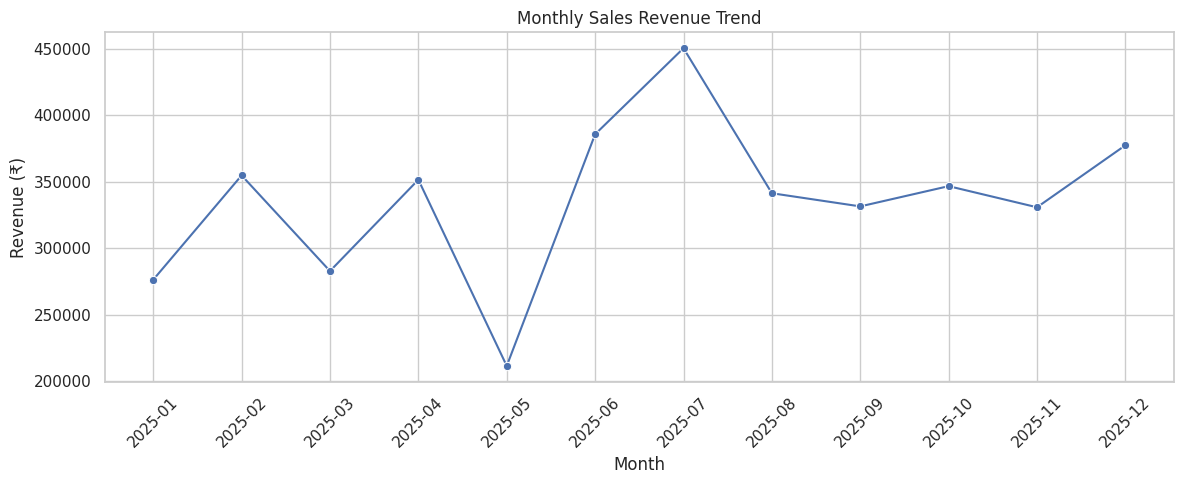

Highest revenue month: 2025-07
Lowest revenue month: 2025-05


In [3]:
monthly = df.groupby('Month', as_index=False)['Revenue'].sum()
monthly.to_csv(OUT / 'monthly_sales.csv', index=False)
fig, ax = plt.subplots(figsize=(12,5))
sns.lineplot(data=monthly, x='Month', y='Revenue', marker='o', ax=ax)
ax.set(title='Monthly Sales Revenue Trend', xlabel='Month', ylabel='Revenue (₹)')
ax.tick_params(axis='x', rotation=45); fig.tight_layout(); fig.savefig(OUT/'01_monthly_sales_trend.png', dpi=160); plt.show()
print('Highest revenue month:', monthly.loc[monthly.Revenue.idxmax(), 'Month'])
print('Lowest revenue month:', monthly.loc[monthly.Revenue.idxmin(), 'Month'])

**Observation:** Compare the highest and lowest months when planning stock and promotions. A single synthetic year is not enough to establish a reliable seasonal pattern.

## 4. Quarterly sales trend
Quarterly aggregation smooths some month-to-month variation and supports higher-level planning.

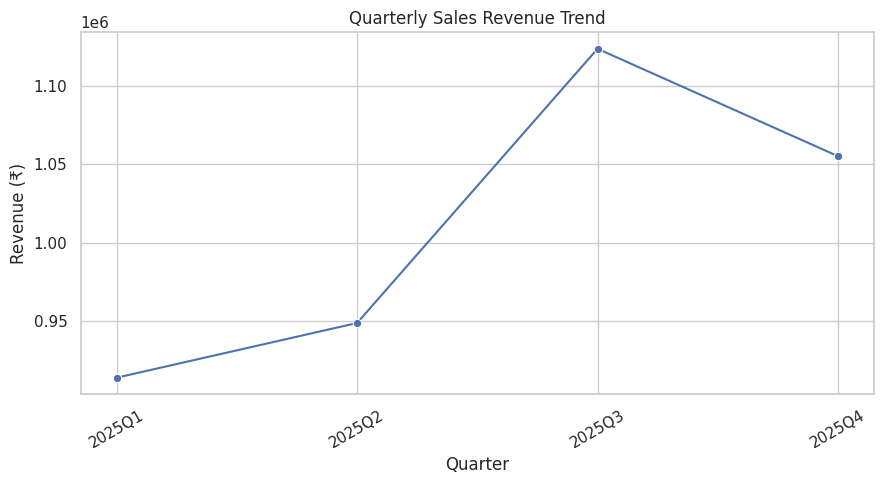

,Quarter,Revenue
0,2025Q1,914190.15
1,2025Q2,949026.23
2,2025Q3,1123658.35
3,2025Q4,1055270.27


In [4]:
quarterly = df.groupby('Quarter', as_index=False)['Revenue'].sum()
quarterly.to_csv(OUT/'quarterly_sales.csv', index=False)
fig, ax = plt.subplots(figsize=(9,5)); sns.lineplot(data=quarterly, x='Quarter', y='Revenue', marker='o', ax=ax)
ax.set(title='Quarterly Sales Revenue Trend', xlabel='Quarter', ylabel='Revenue (₹)'); ax.tick_params(axis='x', rotation=30)
fig.tight_layout(); fig.savefig(OUT/'02_quarterly_sales_trend.png', dpi=160); plt.show(); display(quarterly)

**Observation:** Use the quarterly peaks and dips as a prompt to investigate product availability, discounts, and campaign timing. Do not infer the cause from this chart alone.

## 5. Customer age-group distribution

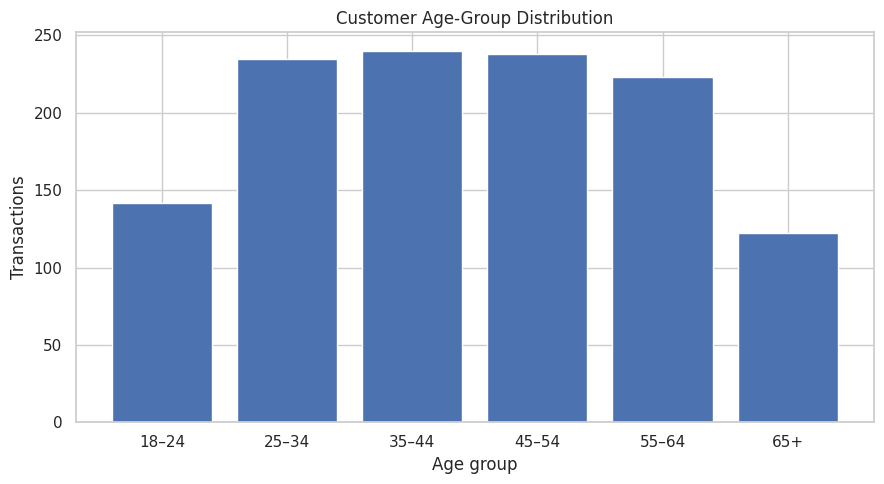

,AgeGroup,Transactions
0,18–24,142
1,25–34,235
2,35–44,240
3,45–54,238
4,55–64,223
5,65+,122


In [5]:
age_counts = df['AgeGroup'].value_counts().sort_index().rename_axis('AgeGroup').reset_index(name='Transactions')
age_counts['AgeGroup'] = age_counts['AgeGroup'].astype(str)
age_counts.to_csv(OUT/'age_group_distribution.csv', index=False)
fig, ax = plt.subplots(figsize=(9,5)); ax.bar(age_counts['AgeGroup'], age_counts['Transactions'])
ax.set(title='Customer Age-Group Distribution', xlabel='Age group', ylabel='Transactions'); fig.tight_layout(); fig.savefig(OUT/'03_age_group_distribution.png', dpi=160); plt.show(); display(age_counts)

**Observation:** Transaction counts show which age groups appear more frequently in this sample; they do not necessarily indicate population size, profitability, or conversion rate.

## 6. Gender breakdown

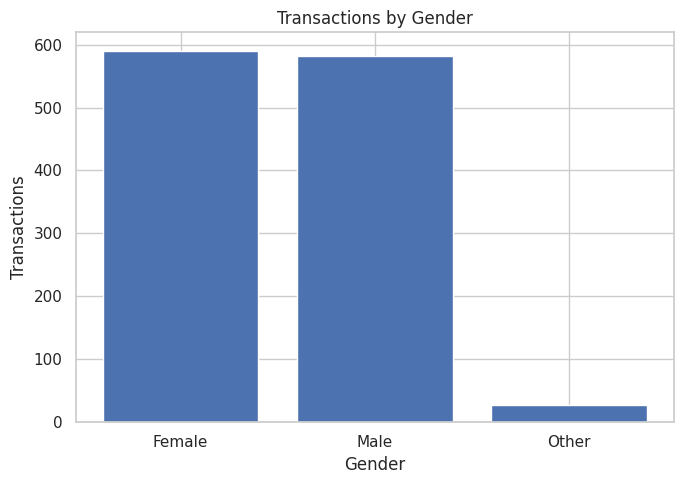

,Gender,Transactions
0,Female,590
1,Male,582
2,Other,28


In [6]:
gender = df['Gender'].value_counts().rename_axis('Gender').reset_index(name='Transactions')
gender.to_csv(OUT/'gender_breakdown.csv', index=False)
fig, ax = plt.subplots(figsize=(7,5)); ax.bar(gender['Gender'], gender['Transactions'])
ax.set(title='Transactions by Gender', xlabel='Gender', ylabel='Transactions'); fig.tight_layout(); fig.savefig(OUT/'04_gender_breakdown.png', dpi=160); plt.show(); display(gender)

**Observation:** Treat demographic breakdown as descriptive only. Any demographic campaign should be tested fairly and evaluated with relevant outcomes.

## 7. Top 10 best-selling products

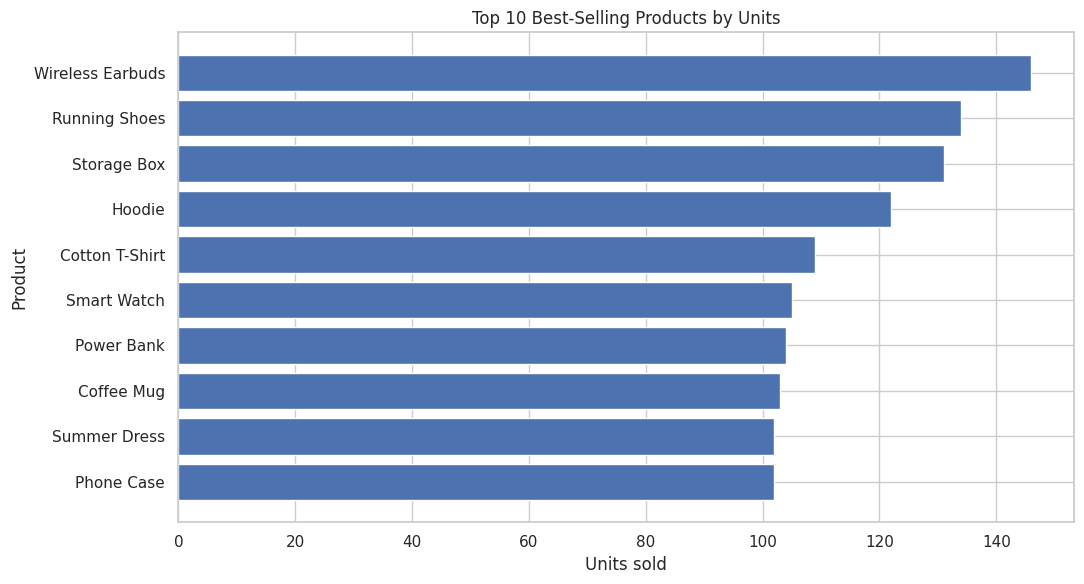

,Product,UnitsSold,Revenue
25,Wireless Earbuds,146,507136.85
15,Running Shoes,134,182725.37
19,Storage Box,131,174157.38
8,Hoodie,122,195556.52
4,Cotton T-Shirt,109,162299.56
18,Smart Watch,105,336649.13
14,Power Bank,104,336238.04
1,Coffee Mug,103,121837.09
20,Summer Dress,102,152006.94
13,Phone Case,102,357324.85


In [7]:
top_products = df.groupby('Product', as_index=False).agg(UnitsSold=('Quantity','sum'), Revenue=('Revenue','sum')).sort_values('UnitsSold', ascending=False).head(10)
top_products.to_csv(OUT/'top_10_products.csv', index=False)
fig, ax = plt.subplots(figsize=(11,6)); plot_products = top_products.sort_values('UnitsSold')
ax.barh(plot_products['Product'], plot_products['UnitsSold'])
ax.set(title='Top 10 Best-Selling Products by Units', xlabel='Units sold', ylabel='Product'); fig.tight_layout(); fig.savefig(OUT/'05_top_10_products.png', dpi=160); plt.show(); display(top_products)

**Observation:** Products are ranked by units sold, not revenue. Use both unit volume and margin before deciding what to promote or reorder.

## 8. Revenue by product category

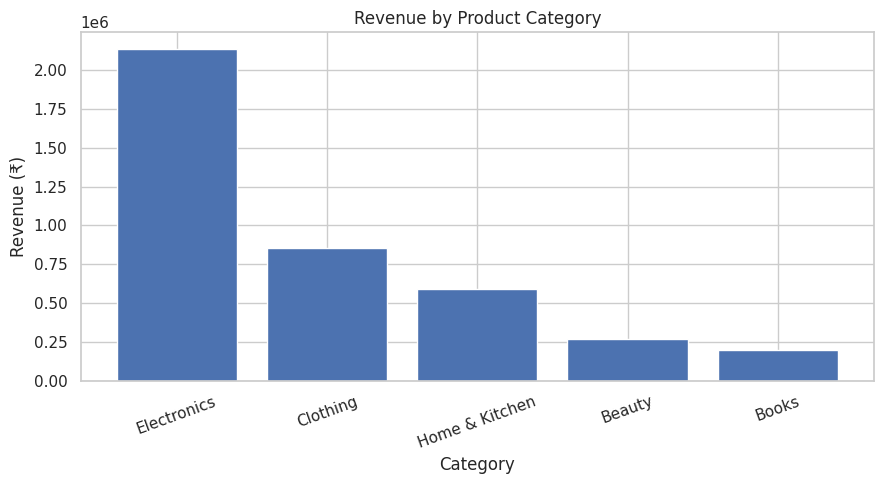

,Category,Revenue
3,Electronics,2136734.55
2,Clothing,852012.41
4,Home & Kitchen,591352.71
0,Beauty,266758.55
1,Books,195286.78


In [8]:
category = df.groupby('Category', as_index=False)['Revenue'].sum().sort_values('Revenue', ascending=False)
category.to_csv(OUT/'category_revenue.csv', index=False)
fig, ax = plt.subplots(figsize=(9,5)); ax.bar(category['Category'], category['Revenue'])
ax.set(title='Revenue by Product Category', xlabel='Category', ylabel='Revenue (₹)'); ax.tick_params(axis='x', rotation=20)
fig.tight_layout(); fig.savefig(OUT/'06_category_revenue.png', dpi=160); plt.show(); display(category)

**Observation:** The leading category by revenue may differ from the category with the most units sold because unit prices vary.

## 9. Correlation heatmap

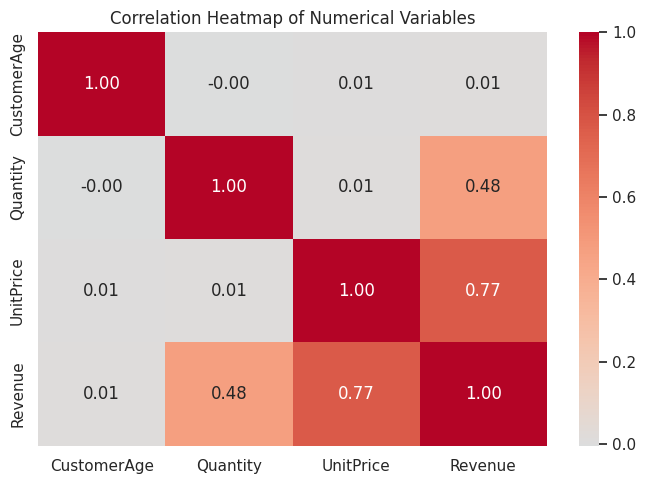

,CustomerAge,Quantity,UnitPrice,Revenue
CustomerAge,1.00,-0.00,0.01,0.01
Quantity,-0.00,1.00,0.01,0.48
UnitPrice,0.01,0.01,1.00,0.77
Revenue,0.01,0.48,0.77,1.00


In [9]:
corr_cols = ['CustomerAge','Quantity','UnitPrice','Revenue']
corr = df[corr_cols].corr(numeric_only=True); corr.to_csv(OUT/'correlation_matrix.csv')
fig, ax = plt.subplots(figsize=(7,5)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set(title='Correlation Heatmap of Numerical Variables'); fig.tight_layout(); fig.savefig(OUT/'07_correlation_heatmap.png', dpi=160); plt.show(); display(corr.round(2))

**Observation:** Correlation measures linear association, not causation. Revenue is mathematically tied to quantity and unit price because it is calculated as Quantity × UnitPrice.

## 10. Additional visualisation — payment method and average transaction revenue

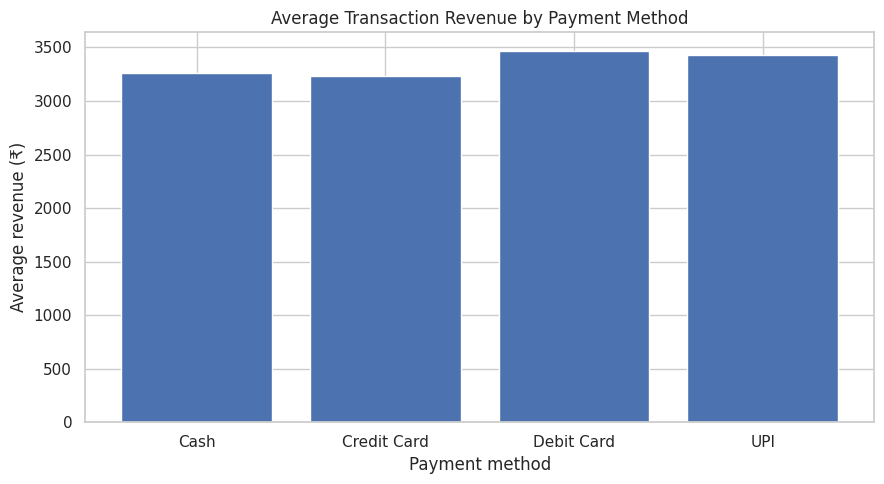

,PaymentMethod,Transactions,AverageRevenue
0,Cash,122,3265.15
1,Credit Card,319,3228.99
2,Debit Card,238,3467.49
3,UPI,521,3432.79


In [10]:
payment = df.groupby('PaymentMethod', as_index=False).agg(Transactions=('TransactionID','count'), AverageRevenue=('Revenue','mean'))
payment.to_csv(OUT/'payment_method_analysis.csv', index=False)
fig, ax = plt.subplots(figsize=(9,5)); ax.bar(payment['PaymentMethod'], payment['AverageRevenue'])
ax.set(title='Average Transaction Revenue by Payment Method', xlabel='Payment method', ylabel='Average revenue (₹)'); fig.tight_layout(); fig.savefig(OUT/'08_payment_method_average_revenue.png', dpi=160); plt.show(); display(payment.round(2))

**Observation:** Differences in average transaction value may reflect customer mix or order composition, not the payment method itself. Further investigation is needed before making checkout changes.

## 11. Conclusion and actionable recommendations
1. Keep the leading products available and test product-page placement or bundles; compare results before scaling.
2. Review the category contributing the most revenue and test targeted promotions while tracking profit margin, not revenue alone.
3. Use monthly and quarterly peaks to plan stock and staffing, then validate with multiple years of real sales data.
4. Investigate customer and payment-method patterns with conversion and margin data before personalising campaigns.

**Limitation:** The included data is synthetic and is only for demonstrating the analysis workflow. Replace it with a suitable real retail dataset before presenting business conclusions as factual.

In [11]:
summary = {
 'transactions': len(df),
 'total_units_sold': int(df['Quantity'].sum()),
 'total_revenue': round(float(df['Revenue'].sum()), 2),
 'average_transaction_revenue': round(float(df['Revenue'].mean()), 2),
 'missing_cells': int(df.isna().sum().sum()),
 'duplicate_rows': int(df.duplicated().sum()),
 'top_product_by_units': str(top_products.iloc[0]['Product']),
 'top_category_by_revenue': str(category.iloc[0]['Category'])
}
summary_df = pd.DataFrame({'Metric': summary.keys(), 'Value': summary.values()})
summary_df.to_csv(OUT/'project_kpi_summary.csv', index=False)
display(summary_df)
print('Charts and tables saved to:', OUT.resolve())

,Metric,Value
0,transactions,1200
1,total_units_sold,2437
2,total_revenue,4042145.0
3,average_transaction_revenue,3368.45
4,missing_cells,0
5,duplicate_rows,0
6,top_product_by_units,Wireless Earbuds
7,top_category_by_revenue,Electronics


Charts and tables saved to: /mnt/data/OIBSIP/DataAnalytics-L1-EDARetailSales/outputs
